In [1]:
# 01Chargement des bibliothèques
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import joblib
import matplotlib.pyplot as plt

In [2]:
# 02Chargement des données
df = pd.read_csv('/kaggle/input/house-prices-advanced-regression-techniques/train.csv')
print(df.shape)
df.head()


(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
# 03 Sélection des features numériques & nettoyage
# Garder uniquement les variables numériques
df_num = df.select_dtypes(include=['number'])

# Supprimer les lignes contenant des valeurs manquantes
df_num = df_num.dropna()

df_num.shape


(1121, 38)

In [4]:
# 05 Séparation X / y
X = df_num.drop('SalePrice', axis=1)
y = df_num['SalePrice']


In [12]:
# 06 Stratification par binning + Split train/test
#Pourquoi faire un binning ?
# Pour éviter que les tranches de prix très élevées soient mal représentées dans le jeu de test

# Création de catégories de prix (bins)
y_binned = pd.cut(y, bins=10, labels=False)

# Split avec stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y_binned
)


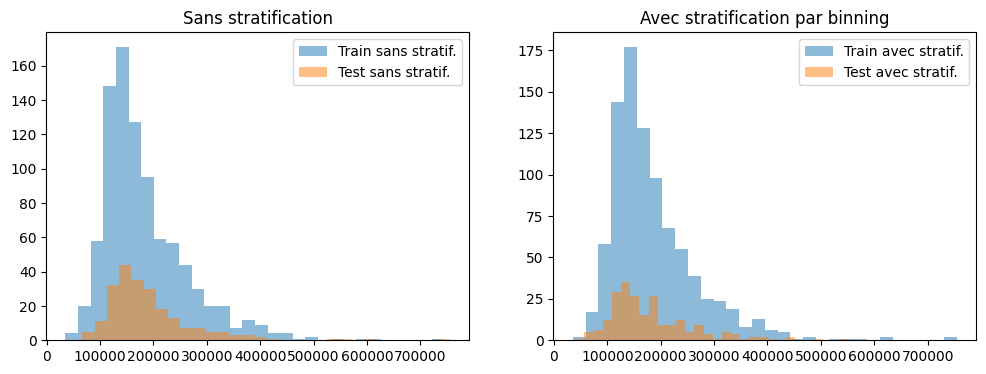

In [13]:
# --- Visualisation ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y_train_ns, bins=30, alpha=0.5, label='Train sans stratif.')
axes[0].hist(y_test_ns, bins=30, alpha=0.5, label='Test sans stratif.')
axes[0].set_title("Sans stratification")
axes[0].legend()

axes[1].hist(y_train, bins=30, alpha=0.5, label='Train avec stratif.')
axes[1].hist(y_test, bins=30, alpha=0.5, label='Test avec stratif.')
axes[1].set_title("Avec stratification par binning")
axes[1].legend()

plt.show()

In [14]:
#Entraînement du modèle
model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

In [15]:
#Évaluation du modèle
# Prédictions
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# Scores
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

print(f"Train RMSE: {rmse_train:.2f}, R2: {r2_train:.3f}")
print(f"Test  RMSE: {rmse_test:.2f}, R2: {r2_test:.3f}")


Train RMSE: 37518.06, R2: 0.797
Test  RMSE: 31279.82, R2: 0.852


In [16]:
#Sauvegarde du modèle
joblib.dump(model, 'model.pkl')


['model.pkl']